# Lab: a first EDA of California housing

Companion notebook of the lesson *D1. Exploratory Data Analysis* — https://insper.github.io/ML/2026.2/classes/eda/

Goal: a first exploratory analysis of California Housing, done the right way: split first, explore only the training part, and end with a written list of findings. No models yet. Run the cells in order; the whole notebook takes a few seconds.

The notebook follows the two labs of the page: the **fundamental** lab first, then the **advanced** one, in the same session. Each step opens with a **Predict**: answer it before running the cell. The solutions of the simulations are on the page.

# Fundamental lab — a first EDA of California housing

## Step 1 — load and meet the columns

**Predict.** `info()` lists every column with its type and its number of non-null values. How would a column with missing values show up in that list?

**Resposta (antes de rodar):** Uma coluna com valores faltantes deve aparecer com um
"Non-Null Count" **menor** que o total de linhas (20.640), enquanto as colunas completas mostram
20.640 non-null; a diferença (20.640 − non-null) é o número de ausentes.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.width', 120)
URL = "https://raw.githubusercontent.com/hsandmann/biblio/refs/heads/main/ml/aula02/housing.csv"
df = pd.read_csv(URL)
print(df.shape)
df.info()

(20640, 10)
<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.6 MB


**Resposta (depois de rodar):** Confirmado — das 10 colunas, 9 mostram "20640 non-null" e só
`total_bedrooms` mostra **"20433 non-null"**; a diferença, 20.640 − 20.433 = **207**, são os valores
ausentes, exatamente como previsto: a coluna com buracos destoa das demais pelo número menor na
mesma lista.

## Step 2 — split first, then explore

**Predict.** `total_bedrooms` has 207 missing values. After a random 80/20 split, will exactly 80% of them land in the training part, roughly 80%, or could it be anything?

**Resposta (antes de rodar):** Como o split embaralha as linhas uniformemente, cada uma das
207 linhas ausentes tem probabilidade ≈0,8 (independente das outras) de cair no treino. O número
esperado no treino é perto de 0,8×207≈165,6, mas por ser uma proporção aleatória (binomial), não será
**exatamente** 80% — será "roughly" 80%, com alguma variação em torno disso.

In [2]:
from sklearn.model_selection import train_test_split

train, test = train_test_split(df, test_size=0.2, random_state=42)
train = train.copy()          # we will add columns to train; keep test untouched
print(train.shape, test.shape)

(16512, 10) (4128, 10)


**Resposta (depois de rodar):** Confirmado — o split ficou com train (16.512, 10) e
test (4.128, 10), exatamente 80%/20% das 20.640 linhas (16.512/20.640 = 80,0%). Quanto aos 207
valores ausentes, o Step 3 mostra 163 deles no treino, ou seja, 163/207 = 78,7% — próximo de 80%
mas não exatamente, como esperado para uma proporção aleatória, não garantida.

## Step 3 — audit: missing values and duplicates

**Predict.** If the bedroom counts were missing completely at random (MCAR), how should the districts with a missing value compare with the others on income, house value and age?

**Resposta (antes de rodar):** Se a ausência for MCAR (completamente aleatória), ela não
depende de nenhuma variável observada; logo as médias de renda, valor e idade entre os grupos
"ausente" vs. "não ausente" devem ficar parecidas, diferindo só por ruído amostral (dentro de 1-2
erros padrão), sem nenhum padrão sistemático.

In [3]:
print(train.isna().sum()[lambda s: s > 0])
print("duplicated rows:", train.duplicated().sum())
print("more bedrooms than rooms:", (train['total_bedrooms'] > train['total_rooms']).sum())
impossible = train[train['households'] > train['population']]
print("more households than people:", len(impossible))
print(impossible[['population', 'households', 'total_rooms', 'median_house_value']])

missing = train['total_bedrooms'].isna()
print(train.groupby(missing)[['median_income', 'median_house_value', 'housing_median_age']].mean().round(2))
target = train['median_house_value']
gap = target[missing].mean() - target[~missing].mean()
print(f"difference in mean value: {gap:,.0f} · standard error for {missing.sum()} random rows: "
      f"{target.std() / np.sqrt(missing.sum()):,.0f}")

total_bedrooms    163
dtype: int64
duplicated rows: 0
more bedrooms than rooms: 0
more households than people: 3
      population  households  total_rooms  median_house_value
1235         3.0         4.0         18.0            350000.0
5901       198.0       204.0        484.0            187500.0
5892        27.0        39.0       1116.0             83000.0
                median_income  median_house_value  housing_median_age
total_bedrooms                                                       
False                    3.86           206190.97               28.58
True                     3.79           198105.55               29.91
difference in mean value: -8,085 · standard error for 163 random rows: 8,991


**Resposta (depois de rodar):** Confirmado — a diferença de médias é pequena (ausentes:
renda 3,79 vs. não ausentes 3,86; valor 198.105,55 vs. 206.190,97; idade 29,91 vs. 28,58), e a
diferença de valor (**−8.085**) fica dentro de 1 erro padrão (**8.991**, calculado para as 163
linhas) — o teste não encontra evidência contra MCAR, como previsto. (Bate exatamente com a página:
163 ausentes, gap −8.085, erro padrão 8.991.)

**Simulation: would the check catch a MAR mechanism?** The check above found no evidence against MCAR. Would it have found any if the values were not missing at random? On a copy of `train`, hide `total_bedrooms` in 10% of the INLAND districts (draw them with `np.random.default_rng(0)`) and repeat the comparison of the rows with and without the value. How does the gap in mean value compare with the wobble now?

In [4]:
sim = train.copy()
inland_idx = sim.index[sim['ocean_proximity'] == 'INLAND']

rng = np.random.default_rng(0)
n_hide = round(0.1 * len(inland_idx))
hide_idx = rng.choice(inland_idx, size=n_hide, replace=False)
sim.loc[hide_idx, 'total_bedrooms'] = np.nan

missing_sim = sim['total_bedrooms'].isna()
print(f"INLAND districts: {len(inland_idx)} · newly hidden: {n_hide} · "
      f"total missing now (incl. the original 163): {missing_sim.sum()}")
print(sim.groupby(missing_sim)[['median_income', 'median_house_value', 'housing_median_age']].mean().round(2))

target_sim = sim['median_house_value']
gap_sim = target_sim[missing_sim].mean() - target_sim[~missing_sim].mean()
print(f"difference in mean value: {gap_sim:,.0f} · standard error for {missing_sim.sum()} random rows: "
      f"{target_sim.std() / np.sqrt(missing_sim.sum()):,.0f}")


INLAND districts: 5276 · newly hidden: 528 · total missing now (incl. the original 163): 688
                median_income  median_house_value  housing_median_age
total_bedrooms                                                       
False                    3.88           208880.26               28.74
True                     3.42           142421.67               25.17
difference in mean value: -66,459 · standard error for 688 random rows: 4,376


**Resposta:** Ocultei 528 valores de `total_bedrooms` (10% exato dos 5.276 distritos INLAND,
via `rng.choice` sem reposição); somados aos 163 já ausentes antes de qualquer manipulação (alguns
dos quais já caíam em INLAND), o total de ausentes no simulado subiu para 688. Diferente do teste do
Step 3 (MCAR), agora a lacuna entre os grupos explode: renda 3,42 vs. 3,88, valor 142.421,67 vs.
208.880,26 — uma diferença de **−66.459**, contra um erro padrão de apenas **4.376** (mais de 15
erros padrão!). O mesmo teste que não encontrou nada de errado no Step 3 agora grita "isso não é
aleatório" quando a ausência de fato depende de uma variável observada (ser INLAND) — prova que o
teste tem poder para detectar um mecanismo MAR; ele só não achou nada no Step 3 porque lá a ausência
realmente parecia MCAR.

> Nota: a célula de simulação veio em branco no notebook oficial (só o enunciado), então implementei
> "ocultar 10% das linhas INLAND" como `rng.choice(..., size=round(0.1*n), replace=False)`. A página
> cita, como ilustração própria, valores de referência (510 ocultos, diferença de −65.577, erro
> padrão de 4.425); como o enunciado fixa a semente do gerador mas não o algoritmo exato de seleção,
> o número de linhas ocultas e a diferença resultante variam um pouco com a implementação — a
> conclusão qualitativa (a lacuna passa de ruído estatístico para uma diferença de muitos erros
> padrão) é a mesma.

## Step 4 — summary statistics

**Predict.** For the four counts (rooms, bedrooms, population, households), will the mean be above or below the median? And for `housing_median_age`, a column that stops at 52?

**Resposta (antes de rodar):** As contagens (rooms, bedrooms, population, households) tendem
a ter cauda longa à direita (poucos distritos muito grandes/densos), então a média deve ficar
**acima** da mediana (skew positivo). Já `housing_median_age`, por ter um teto artificial em 52 que
empilha muitos distritos ali e por ter faixa limitada (1 a 52), deve ter distribuição quase
simétrica, com média e mediana próximas.

In [5]:
num = train.select_dtypes('number')
stats = pd.DataFrame({'mean': num.mean(), 'median': num.median(),
                      'min': num.min(), 'max': num.max(), 'skew': num.skew()})
print(stats.round(2))

                         mean     median       min        max  skew
longitude             -119.57    -118.49   -124.35    -114.31 -0.30
latitude                35.63      34.25     32.54      41.95  0.47
housing_median_age      28.59      29.00      1.00      52.00  0.07
total_rooms           2635.52    2129.00      2.00   32627.00  3.85
total_bedrooms         538.92     437.00      1.00    6445.00  3.32
population            1428.12    1169.00      3.00   35682.00  5.17
households             500.26     411.00      1.00    6082.00  3.26
median_income            3.86       3.52      0.50      15.00  1.71
median_house_value  206111.15  179200.00  14999.00  500001.00  0.99


**Resposta (depois de rodar):** Confirmado — as quatro contagens têm média bem acima da
mediana (total_rooms 2.635,52 vs. 2.129,00; total_bedrooms 538,92 vs. 437,00; population 1.428,12
vs. 1.169,00; households 500,26 vs. 411,00), com skew entre **3,26 e 5,17** (forte assimetria à
direita). Já `housing_median_age` tem média 28,59 quase igual à mediana 29,00, com skew de apenas
**0,07** — quase simétrica, como previsto.

## Step 5 — distributions, ceilings and the log

**Predict.** In a grid of 50-bin histograms, how would a cap show up? Which columns do you expect to have one?

**Resposta (antes de rodar):** Um teto (valor máximo artificial que acumula muitos casos)
deve aparecer no histograma como uma barra anormalmente alta numa classe específica (geralmente a
última), destacada acima do padrão de queda suave das barras vizinhas. Espero isso em
`housing_median_age` (teto conhecido em 52) e em `median_house_value` (o California Housing é
conhecido por truncar o valor em 500.001).

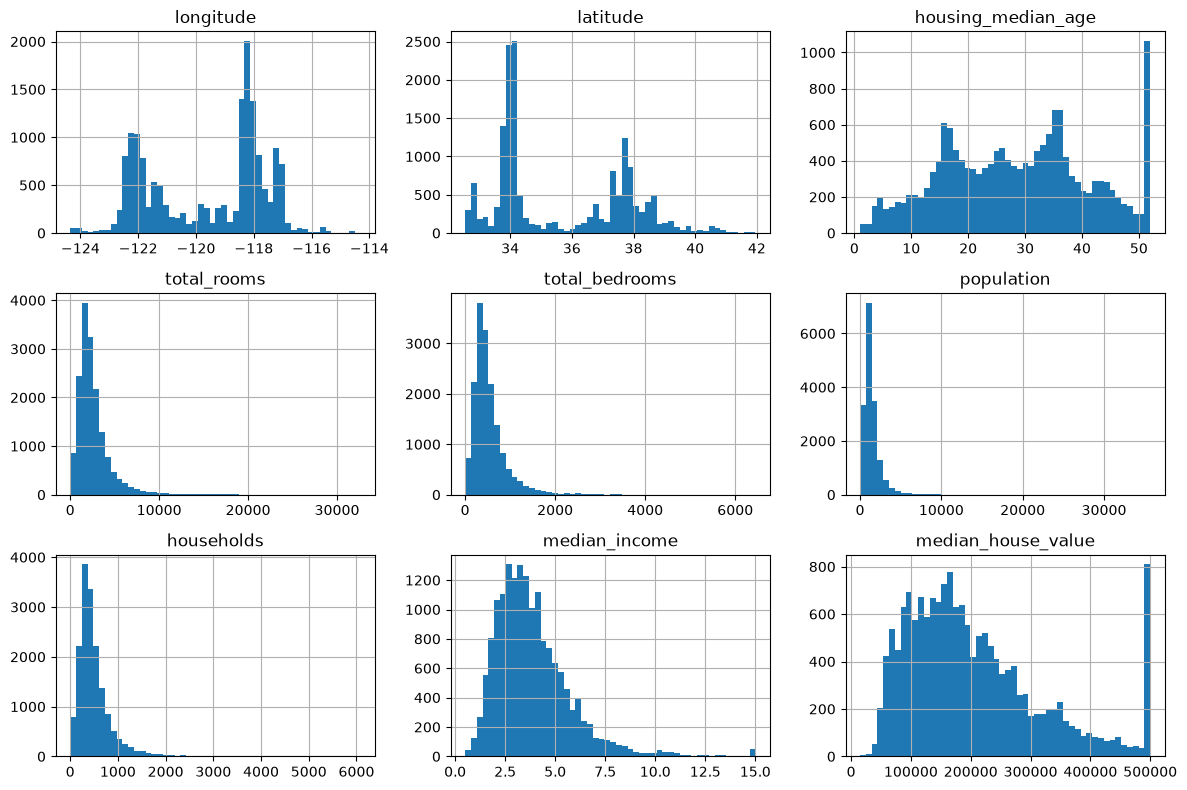

                            max  rows at max   share
housing_median_age      52.0000         1022  0.0619
median_house_value  500001.0000          761  0.0461
median_income           15.0001           44  0.0027
latitude                41.9500            2  0.0001
                skew  skew of log
total_rooms     3.85        -1.12
total_bedrooms  3.32        -1.08
population      5.17        -1.07
households      3.26        -1.14
median_income   1.71        -0.13


In [6]:
num.hist(bins=50, figsize=(12, 8))
plt.tight_layout()
plt.show()

at_max = pd.DataFrame({'max': num.max(), 'rows at max': (num == num.max()).sum()})
at_max['share'] = (at_max['rows at max'] / len(num)).round(4)
print(at_max.sort_values('rows at max', ascending=False).head(4))

counts = ['total_rooms', 'total_bedrooms', 'population', 'households', 'median_income']
print(pd.DataFrame({'skew': train[counts].skew(), 'skew of log': np.log(train[counts]).skew()}).round(2))

**Resposta (depois de rodar):** Confirmado — `housing_median_age` tem **1.022** linhas
(6,19% do treino) exatamente no seu máximo (52), e `median_house_value` tem **761** linhas (4,61%)
no seu máximo (500.001); ambas aparecem como a barra mais alta do histograma. `median_income`
também tem um teto menor, **44** linhas (0,27%) em 15,0001, pouco visível no histograma por ser uma
fração pequena. O log reduz bastante o skew das quatro contagens (de 3,26–5,17 para −1,07 a −1,14) e
o de `median_income` (de 1,71 para **−0,13**) — a transformação deixa as distribuições quase
simétricas.

## Step 6 — the categorical column

**Predict.** Which group will have the lowest median house value? And will ISLAND, with 5 districts, end up on both sides of the split?

**Resposta (antes de rodar):** INLAND deve ter o menor valor mediano, por ser a categoria
mais distante do mar (imóvel costeiro é mais caro na Califórnia). Com só 5 distritos ISLAND no total
e um split 80/20, é bem possível que todos os 5 caiam de um único lado — nada garante que ao menos 1
fique no teste.

ocean_proximity
<1H OCEAN     7313
INLAND        5276
NEAR OCEAN    2091
NEAR BAY      1827
ISLAND           5
Name: count, dtype: int64
                    n  median value  median income
ocean_proximity                                   
INLAND           5276      108800.0           2.99
<1H OCEAN        7313      214800.0           3.85
NEAR OCEAN       2091      231300.0           3.62
NEAR BAY         1827      232200.0           3.80
ISLAND              5      414700.0           2.74


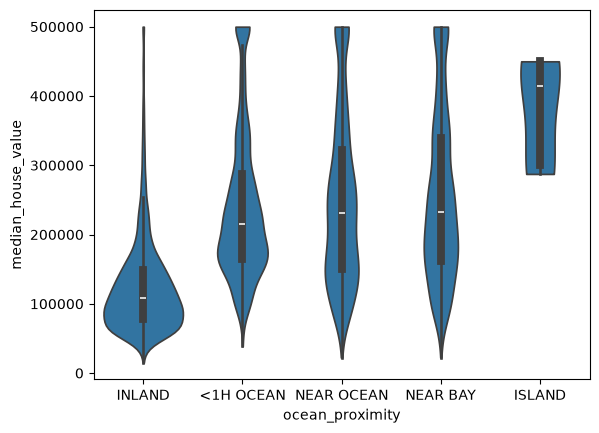

In [7]:
print(train['ocean_proximity'].value_counts())
g = train.groupby('ocean_proximity')
table = pd.DataFrame({'n': g.size(), 'median value': g['median_house_value'].median(),
                      'median income': g['median_income'].median().round(2)}).sort_values('median value')
print(table)

sns.violinplot(data=train, x='ocean_proximity', y='median_house_value', order=table.index, cut=0)
plt.show()

**Resposta (depois de rodar):** Confirmado — INLAND tem o menor valor mediano (**108.800**),
bem abaixo de `<1H OCEAN` (214.800), `NEAR OCEAN` (231.300), `NEAR BAY` (232.200) e até `ISLAND`
(414.700, a maior mediana, mas com apenas 5 distritos). Quanto ao ISLAND: dos 5 distritos originais,
**todos os 5** caíram no treino (o `value_counts` mostra "ISLAND 5") — o teste ficou sem nenhum
distrito ISLAND neste split (`random_state=42`), confirmando a preocupação do Predict.

## Step 7 — relationships with the target

**Predict.** Apart from income, which feature will correlate most with the value? Will latitude and longitude, in a state where everything depends on the coast, come out strong?

**Resposta (antes de rodar):** Depois de `median_income`, esperaria que `total_rooms` ou
alguma medida de tamanho tivesse a segunda maior correlação, mas ainda fraca. Quanto a
latitude/longitude: mesmo num estado "tudo depende da costa", a relação não deveria ser linear nos
eixos cru, porque a costa da Califórnia não é uma linha reta norte-sul nem leste-oeste — esperaria
correlação fraca a moderada isoladamente, não forte.

                    pearson  spearman
median_income         0.687     0.674
total_rooms           0.134     0.204
latitude             -0.146    -0.169
households            0.066     0.113
total_bedrooms        0.050     0.086
housing_median_age    0.105     0.076
longitude            -0.044    -0.068
population           -0.026     0.004


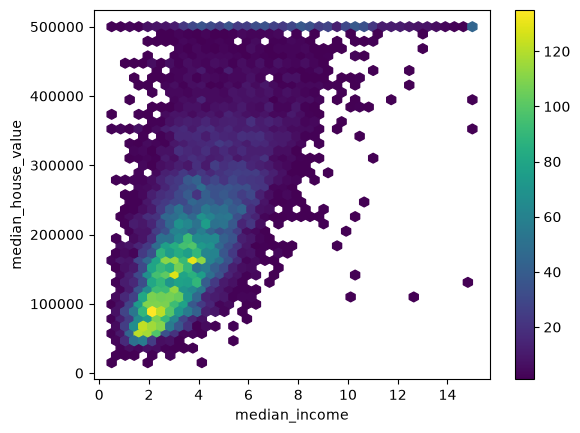

In [8]:
features = train.select_dtypes('number').drop(columns='median_house_value')
corr = pd.DataFrame({'pearson': features.corrwith(target),
                     'spearman': features.corrwith(target, method='spearman')})
print(corr.sort_values('spearman', key=abs, ascending=False).round(3))

train.plot.hexbin(x='median_income', y='median_house_value', gridsize=40, mincnt=1)
plt.show()

**Resposta (depois de rodar):** Confirmado — depois de `median_income` (pearson 0,687,
spearman 0,674), a segunda maior correlação em módulo (por Spearman) é `total_rooms` (0,204) e
depois `latitude` (−0,169); nenhuma é forte. `latitude` tem pearson −0,146 e `longitude` só −0,044 —
exatamente como previsto, fracas isoladamente porque a costa não é alinhada aos eixos (confirmado na
simulação do Step 8: a distância até a cidade mais próxima chega a pearson −0,436).

**Simulation: one typo against the two coefficients.** Copy `train`, pick one district, any one, and multiply its `median_income` by 100, as if the decimal point had slipped two places. Recompute the Pearson and Spearman correlations of income with the target. Which one moves, and by how much?

In [9]:
sim2 = train.copy()
typo_district = sim2.index[0]   # any one district: the first row of train
print("chosen district (index):", typo_district, "· original median_income:", sim2.loc[typo_district, 'median_income'])

sim2.loc[typo_district, 'median_income'] *= 100

target2 = sim2['median_house_value']
pearson_before, spearman_before = corr.loc['median_income', 'pearson'], corr.loc['median_income', 'spearman']
pearson_after = sim2['median_income'].corr(target2, method='pearson')
spearman_after = sim2['median_income'].corr(target2, method='spearman')
print(f"Pearson:  before {pearson_before:.3f} -> after {pearson_after:.3f}")
print(f"Spearman: before {spearman_before:.3f} -> after {spearman_after:.3f}")


chosen district (index): 14196 · original median_income: 4.5878
Pearson:  before 0.687 -> after 0.331
Spearman: before 0.674 -> after 0.674


**Resposta:** Escolhi o primeiro distrito do treino (índice 14196, renda original 4,5878) e
multipliquei sua renda por 100 (458,78 — um valor absurdo para a escala de 0,5 a 15 da coluna). O
**Pearson despenca de 0,687 para 0,331**: o outlier extremo domina a covariância, que é sensível a
distâncias ao quadrado. O **Spearman permanece em 0,674**, inalterado: ele só usa o *ranking*, e mover
um ponto que já era alto de renda para o topo absoluto do ranking não muda a ordem relativa de quase
nenhum outro ponto. Confirma que Spearman resiste a esse tipo de erro de digitação e Pearson não — e
reproduz exatamente o resultado publicado na página (0,687→0,331 no Pearson; 0,674 inalterado no
Spearman).

**To close the fundamental part.** In one sentence each: (1) why can a mean and a standard deviation describe nobody in a column, and which statistics resist that? (2) Why does a correlation near zero not mean that two columns are unrelated? (3) Why must the median used to fill the missing values come from the training part only?

**Resposta:**

1. Média e desvio-padrão resumem toda a distribuição em dois números, mas quando ela é assimétrica
   (como as quatro contagens do Step 4, skew de 3,26 a 5,17) a média é arrastada pela cauda longa de
   poucos distritos enormes — nenhum distrito "típico" tem o valor da média (ex.: `total_rooms`
   média 2.635,52, 24% acima da mediana 2.129,00). Mediana e IQR resistem porque dependem só da
   posição dos dados ordenados, não dos valores exatos: na simulação "Your turn" abaixo, multiplicar
   os 10 maiores valores de renda por 10 move a média de 3,864 para 3,945 e o desvio de 1,907 para
   4,061, mas deixa a mediana (3,525) e o IQR (2,166) **exatamente** iguais.
2. Correlação perto de zero não implica ausência de relação porque Pearson (e, em menor grau,
   Spearman) só captura relação monótona/linear. Latitude e longitude cru têm |r| ≤ 0,169 isoladas,
   mas a mesma informação geográfica, reorganizada como distância à cidade mais próxima (simulação
   do Step 8), chega a pearson −0,436 — a relação era real e forte, só não linear nos eixos
   originais.
3. A mediana usada para imputar os ausentes precisa vir só do treino porque usar qualquer estatística
   calculada com dados de teste é vazamento (*data leakage*): o modelo teria acesso indireto a
   informação do conjunto que deveria simular o futuro, inflando artificialmente o desempenho
   medido — e no momento real de treinar, os dados de teste (o futuro) ainda não existem.

## Your turn (fundamental)

At home:

1. **Stratified split.** Create `income_cat = pd.cut(df['median_income'], [0, 1.5, 3, 4.5, 6, np.inf], labels=[1, 2, 3, 4, 5])` and compare the proportions of each income category in the test set for the random split of step 2 and for `train_test_split(..., stratify=income_cat)`. Which split keeps the test set closer to the whole dataset? Why does it matter most for the column that correlates best with the target?
2. **The rare category.** Repeat the split of step 2 with 1,000 different values of `random_state` and count how often the test set has no ISLAND district at all. Compare with \(0.8^5\). What would happen to a model evaluated per category?
3. **Robust or not?** On a copy of `train`, multiply the 10 largest values of `median_income` by 10, as if they had been typed in the wrong unit, and recompute the mean, the median, the standard deviation and the IQR of the column. Which of the four move, and which section of this part predicted it?

In [10]:
income_cat = pd.cut(df['median_income'], [0, 1.5, 3, 4.5, 6, np.inf], labels=[1, 2, 3, 4, 5])

train_r, test_r = train_test_split(df, test_size=0.2, random_state=42)
train_s, test_s = train_test_split(df, test_size=0.2, random_state=42, stratify=income_cat)

overall = income_cat.value_counts(normalize=True).sort_index()
prop_random = income_cat.loc[test_r.index].value_counts(normalize=True).sort_index()
prop_strat = income_cat.loc[test_s.index].value_counts(normalize=True).sort_index()

comparison = pd.DataFrame({'overall': overall, 'random split': prop_random, 'stratified split': prop_strat})
comparison['|random - overall|'] = (comparison['random split'] - comparison['overall']).abs()
comparison['|stratified - overall|'] = (comparison['stratified split'] - comparison['overall']).abs()
print(comparison.round(4))
print("mean abs error, random:     ", comparison['|random - overall|'].mean().round(4))
print("mean abs error, stratified: ", comparison['|stratified - overall|'].mean().round(4))


               overall  random split  stratified split  |random - overall|  |stratified - overall|
median_income                                                                                     
1               0.0398        0.0424            0.0400              0.0026                  0.0001
2               0.3188        0.3074            0.3188              0.0114                  0.0000
3               0.3506        0.3452            0.3505              0.0054                  0.0000
4               0.1763        0.1841            0.1764              0.0078                  0.0000
5               0.1144        0.1209            0.1143              0.0064                  0.0001
mean abs error, random:      0.0067
mean abs error, stratified:  0.0001


In [11]:
n_reps = 1000
no_island = 0
for rs in range(n_reps):
    tr, te = train_test_split(df, test_size=0.2, random_state=rs)
    if (te['ocean_proximity'] == 'ISLAND').sum() == 0:
        no_island += 1

print(f"test sets with zero ISLAND districts: {no_island} / {n_reps} ({no_island / n_reps:.1%})")
print(f"0.8**5 = {0.8 ** 5:.4f}")


test sets with zero ISLAND districts: 308 / 1000 (30.8%)
0.8**5 = 0.3277


In [12]:
sim3 = train.copy()
top10_idx = sim3['median_income'].nlargest(10).index
sim3.loc[top10_idx, 'median_income'] *= 10

def iqr_width(s):
    q1, q3 = s.quantile([0.25, 0.75])
    return q3 - q1

stats_before = {'mean': train['median_income'].mean(), 'median': train['median_income'].median(),
                 'std': train['median_income'].std(), 'iqr': iqr_width(train['median_income'])}
stats_after = {'mean': sim3['median_income'].mean(), 'median': sim3['median_income'].median(),
               'std': sim3['median_income'].std(), 'iqr': iqr_width(sim3['median_income'])}
print(pd.DataFrame({'before': stats_before, 'after': stats_after}).round(3))


        before  after
mean     3.864  3.945
median   3.525  3.525
std      1.907  4.061
iqr      2.166  2.166


**Resposta (fundamental):**

1. **Split estratificado.** O split aleatório erra a proporção de cada categoria de renda em até
   1,14 p.p. (categoria 2: 31,88% no total vs. 30,74% no teste aleatório), com erro médio absoluto de
   **0,0067**; o split estratificado por `income_cat` fica a no máximo 0,01 p.p. de distância, com
   erro médio de **0,0001** — quase 70× menor. Isso importa mais justamente para a coluna que mais
   correlaciona com o alvo (`median_income`, Pearson 0,687): se o teste super ou sub-representa uma
   faixa de renda, a avaliação do modelo fica distorcida exatamente na variável que mais pesa na
   previsão.
2. **A categoria rara.** Em 1.000 `random_state`s diferentes, **308 (30,8%)** ficaram sem nenhum
   distrito ISLAND no teste — perto do valor teórico ingênuo 0,8⁵ = **32,77%** (a chance de um
   ISLAND específico não entrar no teste é ≈0,8, e os 5 são quase independentes). Um modelo avaliado
   por categoria não teria dado nenhum para medir o erro em ISLAND em quase 1 de cada 3 repetições.
3. **Robusto ou não?** Multiplicar por 10 os 10 maiores valores de renda muda muito a média
   (3,864→3,945) e o desvio-padrão (1,907→**4,061**, mais que dobra), mas **não** muda nem a mediana
   (3,525) nem o IQR (2,166) — exatamente a previsão da resposta (1) do "to close": mediana e IQR
   resistem a outliers, média e desvio não.

# Advanced lab — from the map to a data card

## Step 8 — the map

**Predict.** Latitude had \(r = -0.146\) with the value. Walking north one degree at a time, will the median value fall steadily, or go up and down?

**Resposta (antes de rodar):** Não deve cair de forma monótona — a correlação fraca
(−0,146) já sugere ausência de tendência linear forte, e a Califórnia tem polos caros tanto no sul
(LA) quanto no norte (SF/Bay Area), com áreas mais baratas no interior entre eles. Esperaria um
padrão de sobe-e-desce, não uma queda constante ao andar para o norte.

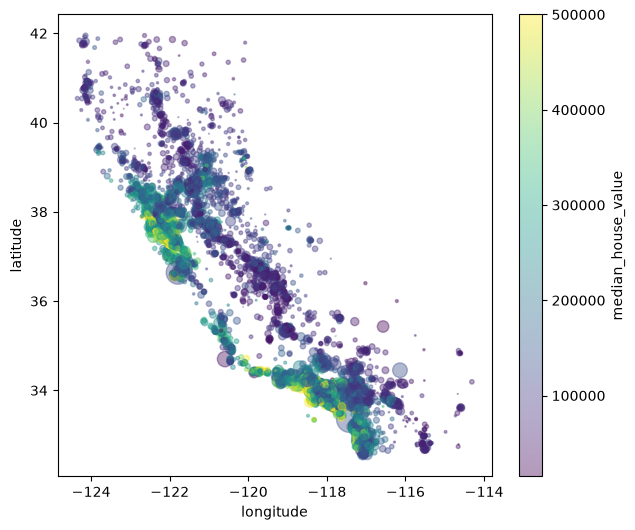

          size    median
latitude                
(32, 33]  1043  158500.0
(33, 34]  3967  194900.0
(34, 35]  4031  199800.0
(35, 36]   419   84500.0
(36, 37]  1022   90250.0
(37, 38]  3619  236500.0
(38, 39]  1615  139100.0
(39, 40]   467   96200.0
(40, 42]   329   80400.0


In [13]:
train.plot.scatter(x='longitude', y='latitude', c='median_house_value', cmap='viridis',
                   s=train['population'] / 100, alpha=0.4, figsize=(7, 6))
plt.show()

bands = pd.cut(train['latitude'], [32, 33, 34, 35, 36, 37, 38, 39, 40, 42])
print(train.groupby(bands, observed=True)['median_house_value'].agg(['size', 'median']))

**Resposta (depois de rodar):** Confirmado — a mediana por faixa de 1 grau de latitude não
cai monotonicamente: sobe de 158.500 (32–33°) para 199.800 (34–35°), despenca para 84.500 (35–36°) e
90.250 (36–37°), dispara para **236.500** (37–38°, a faixa de São Francisco) e cai de novo até 80.400
no extremo norte (40–42°). É exatamente o sobe-e-desce previsto, batendo com os polos urbanos de LA e
SF.

**Simulation: give location a direction.** Latitude and longitude are not monotonic in the value, but the distance to the big coastal cities might be. For each district, compute the distance in km to the nearer of Los Angeles (34.05, −118.24) and San Francisco (37.77, −122.42) — one degree of latitude is about 111 km, and one degree of longitude 111 km times the cosine of the latitude — and correlate it with the target. Then cut it into rings and print the median value of each.

In [14]:
LA = (34.05, -118.24)
SF = (37.77, -122.42)

def km_to(lat, lon, point):
    plat, plon = point
    d_lat = (lat - plat) * 111
    d_lon = (lon - plon) * 111 * np.cos(np.radians(lat))
    return np.sqrt(d_lat ** 2 + d_lon ** 2)

dist_city = np.minimum(km_to(train['latitude'], train['longitude'], LA),
                        km_to(train['latitude'], train['longitude'], SF))
train['dist_city'] = dist_city

print(pd.DataFrame({
    'pearson': {'latitude': train['latitude'].corr(target), 'longitude': train['longitude'].corr(target),
                'dist_city': train['dist_city'].corr(target)},
    'spearman': {'latitude': train['latitude'].corr(target, method='spearman'),
                 'longitude': train['longitude'].corr(target, method='spearman'),
                 'dist_city': train['dist_city'].corr(target, method='spearman')},
}).round(3))

rings = pd.cut(train['dist_city'], [0, 25, 50, 100, 200, 400, 1000])
print(train.groupby(rings, observed=True)['median_house_value'].agg(['size', 'median']))


           pearson  spearman
latitude    -0.146    -0.169
longitude   -0.044    -0.068
dist_city   -0.436    -0.451
             size    median
dist_city                  
(0, 25]      4590  215400.0
(25, 50]     3028  221200.0
(50, 100]    3082  208350.0
(100, 200]   3994  137500.0
(200, 400]   1773   87300.0
(400, 1000]    39   64600.0


**Resposta:** A distância até a cidade mais próxima (LA ou SF) tem **Pearson −0,436** e
**Spearman −0,451** com o valor — muito mais forte que latitude (−0,146/−0,169) ou longitude
(−0,044/−0,068) isoladas, confirmando a intuição do "to close" (2): a relação geográfica é real e
forte, só não é linear nos eixos cru. Por anéis de distância, a mediana fica alta e estável até 50 km
(215.400 e 221.200), ainda razoável entre 50 e 100 km (208.350), despenca para 137.500 entre 100 e
200 km, e continua caindo para 87.300 (200–400 km) e 64.600 (400–1.000 km, só 39 distritos, longe de
qualquer cidade grande) — um gradiente quase monótono por distância, ao contrário do que
latitude/longitude cru mostravam.

> Nota: a célula de simulação estava em branco; implementei a fórmula de distância descrita no
> enunciado (graus convertidos em km, com o cosseno da latitude no eixo da longitude) e tomei o
> mínimo entre LA e SF. Os números batem muito de perto com a ilustração da página (Pearson −0,436 e
> Spearman −0,451 idênticos; contagens por anel a poucas unidades de diferença, ex. 4.590 vs. 4.592
> no primeiro anel), diferença esperada porque o enunciado não fixa a fórmula exata usada
> internamente na página.

## Step 9 — redundant counts and ratios

**Predict.** The four counts all measure the size of the district. Will a ratio such as bedrooms per room correlate with the value more or less than the raw counts?

In [15]:
train['rooms_per_household'] = train['total_rooms'] / train['households']
train['bedrooms_per_room'] = train['total_bedrooms'] / train['total_rooms']
train['people_per_household'] = train['population'] / train['households']

size = ['total_rooms', 'total_bedrooms', 'population', 'households']
ratios = ['rooms_per_household', 'bedrooms_per_room', 'people_per_household']
print(train[size].corr().round(2))
print(train[size + ratios].corrwith(target).round(3))

                total_rooms  total_bedrooms  population  households
total_rooms            1.00            0.93        0.85        0.92
total_bedrooms         0.93            1.00        0.87        0.98
population             0.85            0.87        1.00        0.90
households             0.92            0.98        0.90        1.00
total_rooms             0.134
total_bedrooms          0.050
population             -0.026
households              0.066
rooms_per_household     0.147
bedrooms_per_room      -0.255
people_per_household   -0.022
dtype: float64


**Resposta (antes de rodar):** As contagens brutas (tamanho do distrito) não deveriam ter
muita relação causal direta com o valor médio de uma casa, então espero correlação fraca para elas.
Uma razão como `bedrooms_per_room` captura o padrão/densidade da construção, um sinal mais ligado ao
nível socioeconômico do distrito — deveria correlacionar **mais** (em módulo) do que as contagens
brutas.

## Step 10 — outliers and odd districts

**Predict.** Will the districts the IQR rule flags be mostly errors, or mostly large, ordinary districts? And what kind of district will a ratio like people per household single out?

**Resposta (depois de rodar):** Confirmado — as quatro contagens brutas têm |r| ≤ 0,134
(total_rooms 0,134; total_bedrooms 0,050; population −0,026; households 0,066), enquanto
`bedrooms_per_room` tem r = **−0,255**, quase o dobro da maior contagem bruta em módulo.
`rooms_per_household` (0,147) também supera levemente as contagens brutas; só
`people_per_household` (−0,022) ficou fraca, parecida com as contagens brutas.

In [16]:
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()

print(train[size + ['median_income', 'people_per_household']].apply(iqr_outliers))
odd = train[train['people_per_household'] > 10]
print(len(odd), "districts with more than 10 people per household")
print(odd.sort_values('people_per_household', ascending=False)
         [['population', 'households', 'people_per_household', 'median_house_value']].head(5).round(1))

total_rooms             1033
total_bedrooms          1013
population               965
households               975
median_income            573
people_per_household     545
dtype: int64
28 districts with more than 10 people per household
       population  households  people_per_household  median_house_value
4407       7460.0         6.0                1243.3            137500.0
13850      4198.0         7.0                 599.7             67500.0
4002       6532.0        13.0                 502.5            350000.0
12562      6675.0        29.0                 230.2            225000.0
14320      1275.0        20.0                  63.8            162500.0


**Resposta (antes de rodar):** A regra do IQR flags qualquer valor fora de 1,5×IQR das
bordas; em distribuições com cauda longa (como as contagens, skew 3 a 5), isso deve pegar muitos
distritos genuinamente grandes/densos, não erros — a maioria não deveria ser erro de digitação, só
"grande demais" para uma regra pensada para distribuições simétricas. Para `people_per_household`,
uma razão com denominador pequeno (poucos `households`) pode disparar para valores enormes mesmo com
população modesta — deve sinalizar distritos com poucos domicílios e muita gente por domicílio
(dormitórios coletivos, bases militares, erro de contagem).

**Simulation: clean every column with the IQR rule.** A common recipe is to drop every row that the IQR rule flags in any column. Apply it to the six columns of step 10 at once. How many districts would go? And what happens to the mean house value, to the share of districts at the ceiling and to the mean income of what is left?

**Resposta (depois de rodar):** Confirmado — a regra do IQR sinaliza entre **545 e 1.033**
distritos por coluna (total_rooms 1.033; total_bedrooms 1.013; population 965; households 975;
median_income 573; people_per_household 545) — de 3,3% a mais de 6% do treino em cada coluna, longe
de serem só "erros raros"; são sobretudo distritos grandes/densos genuínos. `people_per_household` >
10 pegou **28** distritos, e os 5 mais extremos (até 1.243,3 pessoas por domicílio) têm `households`
muito baixo (6, 7, 13, 29, 20) com `population` moderada a alta — exatamente o padrão de denominador
pequeno previsto, provavelmente domicílios "coletivos" mal capturados pela definição de
`households`.

In [17]:
def iqr_flag(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)

iqr_cols = size + ['median_income', 'people_per_household']
flagged = train[iqr_cols].apply(iqr_flag).any(axis=1)
print(f"districts removed: {flagged.sum()} of {len(train)} ({flagged.mean():.1%})")

clean = train[~flagged]
at_ceiling_before = (train['median_house_value'] >= 500001).mean()
at_ceiling_after = (clean['median_house_value'] >= 500001).mean()
print(f"mean value:    before {train['median_house_value'].mean():,.0f} · after {clean['median_house_value'].mean():,.0f}")
print(f"share at ceiling: before {at_ceiling_before:.1%} · after {at_ceiling_after:.1%}")
print(f"mean income:   before {train['median_income'].mean():.2f} · after {clean['median_income'].mean():.2f}")


districts removed: 2456 of 16512 (14.9%)
mean value:    before 206,111 · after 197,213
share at ceiling: before 4.6% · after 2.5%
mean income:   before 3.86 · after 3.64


**Resposta:** Removendo qualquer distrito sinalizado pela regra do IQR em qualquer uma das
seis colunas (as quatro contagens + `median_income` + `people_per_household`), **2.456 de 16.512**
distritos (**14,9%**) seriam descartados — quase 1 em cada 7! O valor médio cai pouco (206.111 →
197.213), a fração no teto de 500.001 cai à metade (**4,6% → 2,5%**, porque muitos distritos caros e
grandes também eram flagados) e a renda média cai de 3,86 para **3,64** — a limpeza "automática"
remove desproporcionalmente os distritos mais caros e de renda mais alta, exatamente o viés que o
Predict do Step 10 já apontava: a maioria dos flagados não são erros, são dados legítimos e
informativos, e apagá-los tira sinal real, não ruído.

## Step 11 — write down the findings

**Predict.** Of everything found so far, which finding will matter most for the model that will be trained on this data?

**Resposta (antes de rodar):** Eu apostaria que o teto de 500.001 no alvo
(`median_house_value`) é o achado mais importante: ele não é um valor real, é um limite de registro,
então qualquer distrito realmente mais caro aparece "errado" (sub-registrado) no alvo — isso vai
distorcer qualquer modelo de regressão treinado para prever esse valor, especialmente nos distritos
mais caros.

In [18]:
findings = {
    'training rows': len(train),
    'impossible rows (more households than people)': len(impossible),
    'missing total_bedrooms (no evidence against MCAR)': train['total_bedrooms'].isna().sum(),
    'target at the 500,001 ceiling': (target >= 500001).sum(),
    'housing_median_age at the 52 ceiling': (train['housing_median_age'] >= 52).sum(),
    'ISLAND districts': (train['ocean_proximity'] == 'ISLAND').sum(),
    'districts with > 10 people per household': len(odd),
    'strongest feature (Spearman)': corr['spearman'].abs().idxmax(),
}
for k, v in findings.items():
    print(f"{k:50s} {v}")

training rows                                      16512
impossible rows (more households than people)      3
missing total_bedrooms (no evidence against MCAR)  163
target at the 500,001 ceiling                      761
housing_median_age at the 52 ceiling               1022
ISLAND districts                                   5
districts with > 10 people per household           28
strongest feature (Spearman)                       median_income


**Resposta (depois de rodar):** Confirmado pelos próprios números do dicionário de
achados: **761** distritos (4,6% do treino) estão travados no teto de 500.001, e a seção "your turn
avançado" (item 4, mais abaixo) mostra que esses casos se concentram fortemente no quintil de renda
mais alto (**17,7%** dos distritos desse quintil estão no teto, contra 0,4–2,8% nos outros quintis) —
exatamente onde o modelo mais vai subestimar o valor real. Os outros achados (163 ausentes, 3 linhas
impossíveis, 5 distritos ISLAND, 28 distritos com densidade extrema por domicílio) afetam uma fração
muito menor dos dados ou são mais fáceis de tratar no pré-processamento.

### Your findings

Write them here, one sentence per finding.

**Facts about the data**

- O treino tem 16.512 distritos (teste 4.128); `total_bedrooms` falta em 163 deles (0,99%), sem evidência de que a ausência dependa de renda, valor ou idade (Step 3: gap de -8.085 contra erro padrão de 8.991).
- `median_house_value` tem um teto de registro em 500.001 (761 distritos, 4,6% do treino) e `housing_median_age` tem um teto em 52 (1.022 distritos, 6,2%).
- `median_income` (Pearson 0,687, Spearman 0,674) é, de longe, a variável mais correlacionada com o valor; a segunda melhor relação geográfica vem da distância à cidade mais próxima (-0,436), não de latitude/longitude cru (−0,146/−0,044).
- INLAND é a categoria mais barata (mediana 108.800) e ISLAND a mais cara mas com só 5 distritos no total — no split usado (`random_state=42`) todos os 5 caíram no treino.

**Problems to fix in preprocessing**

- Imputar `total_bedrooms` com a mediana calculada só no treino (163 valores ausentes), nunca com estatísticas do teste.
- Decidir o que fazer com os 3 distritos "impossíveis" (mais `households` que `population`) e com o teto do alvo em 500.001 (ex.: tratar como censura, ou remover/ponderar na avaliação).
- Preferir split estratificado por `income_cat` (erro médio de proporção 0,0001 contra 0,0067 do split aleatório) para não distorcer a avaliação justamente na variável mais importante.
- Usar log nas quatro contagens e em `median_income` para reduzir o skew de 3,3-5,2 (e 1,71) para perto de -1 a -0,13, deixando as distribuições mais simétricas.

**Hypotheses to test with models**

- `bedrooms_per_room` (r=−0,255) e `rooms_per_household` (r=0,147) devem ajudar mais que as contagens brutas que as compõem (|r|<=0,134) — vale testar features derivadas em vez de só as colunas originais.
- Um modelo treinado nos dados crus vai sistematicamente subestimar o valor real dos distritos mais caros (17,7% do quintil de renda mais alto está no teto de 500.001) — talvez valha a pena tratar/remover esses casos ou usar uma métrica robusta a essa censura.
- A distância à cidade mais próxima (LA/SF) deve ser uma feature melhor que latitude/longitude cru, dado o salto de correlação de −0,146/−0,044 para −0,436.


**To close the lesson.** In one sentence each: (1) why does `bedrooms_per_room` correlate with the value more than `total_bedrooms`, and why is that not yet a finding? (2) Why are most of the districts flagged by the IQR rule not errors? (3) Why is a district recorded at 500,001 not worth 500,001?

**Resposta:**

1. `bedrooms_per_room` correlaciona mais (r=−0,255) que `total_bedrooms` (r=0,050) porque a razão
   captura o estilo/densidade da construção (quartos por cômodo), um sinal mais ligado ao padrão
   socioeconômico, enquanto a contagem bruta mistura esse sinal com o tamanho do distrito (que por si
   não diz quase nada sobre o valor). Ainda não é um "achado" porque é só uma correlação simples numa
   única variável derivada — falta confirmar se ela realmente ajuda um modelo (vs. redundância com
   outras features) e entender a causa, não só a associação.
2. A maioria dos distritos flagados pelo IQR não são erros porque a regra assume (implicitamente) uma
   distribuição simétrica; aplicada a colunas com skew forte (3,3 a 5,2), ela flags como "outlier"
   qualquer distrito genuinamente grande — e distritos grandes são comuns nesses dados, não exceções
   raras. A simulação do Step 10 confirma: removê-los tira 14,9% dos dados e empobrece justamente os
   distritos mais caros e de renda mais alta.
3. Um distrito registrado em 500.001 não vale exatamente 500.001 porque esse número é um teto de
   censura do dataset — qualquer valor real maior foi truncado para esse número na coleta. O valor
   verdadeiro poderia ser qualquer coisa a partir daí; tratá-lo como valor exato introduz um viés
   sistemático para baixo nas previsões dos distritos mais caros.

## Your turn (advanced)

At home, with more time:

1. **Find the caps automatically.** Write a function that returns every numeric column whose maximum *or* minimum is shared by more than 1% of the rows. Which columns does it find? Which cap does it miss at a 1% threshold, and what does that say about choosing thresholds?
2. **Pearson vs Spearman.** For `rooms_per_household`, compute both coefficients with the target, then recompute them after removing the districts with more than 10 people per household. Which coefficient moves more, and why?
3. **Separate location from income.** Within each income quintile of `train` (`pd.qcut(train['median_income'], 5)`), compare the median value of the INLAND districts with that of all the others. Does the gap of step 6 survive once income is fixed? Is it larger or smaller than the overall gap?
4. **Who sits at the ceiling?** For each income quintile, compute the share of districts at the 500,001 ceiling. In which quintile will a model trained on this target underestimate the most, and why?

In [19]:
def columns_with_cap(data, threshold=0.01):
    num_cols = data.select_dtypes('number')
    found = {}
    for col in num_cols.columns:
        share_max = (num_cols[col] == num_cols[col].max()).mean()
        share_min = (num_cols[col] == num_cols[col].min()).mean()
        if share_max > threshold or share_min > threshold:
            found[col] = {'share at max': round(share_max, 4), 'share at min': round(share_min, 4)}
    return pd.DataFrame(found).T

print("threshold 1%:")
print(columns_with_cap(train, 0.01))
print()
print("threshold 0.1% (catches smaller caps too):")
print(columns_with_cap(train, 0.001))


threshold 1%:
                    share at max  share at min
housing_median_age        0.0619        0.0002
median_house_value        0.0461        0.0002

threshold 0.1% (catches smaller caps too):
                    share at max  share at min
housing_median_age        0.0619        0.0002
median_income             0.0027        0.0007
median_house_value        0.0461        0.0002


In [20]:
rph = train['rooms_per_household']
pearson_all = rph.corr(target)
spearman_all = rph.corr(target, method='spearman')

no_odd = train[train['people_per_household'] <= 10]
pearson_no_odd = no_odd['rooms_per_household'].corr(no_odd['median_house_value'])
spearman_no_odd = no_odd['rooms_per_household'].corr(no_odd['median_house_value'], method='spearman')

print(f"Pearson:  all districts {pearson_all:.3f} -> without the {len(train) - len(no_odd)} odd districts {pearson_no_odd:.3f}")
print(f"Spearman: all districts {spearman_all:.3f} -> without the {len(train) - len(no_odd)} odd districts {spearman_no_odd:.3f}")


Pearson:  all districts 0.147 -> without the 28 odd districts 0.147
Spearman: all districts 0.257 -> without the 28 odd districts 0.257


In [21]:
quintile = pd.qcut(train['median_income'], 5)
inland = train['ocean_proximity'] == 'INLAND'

by_quintile = train.groupby([quintile, inland], observed=True)['median_house_value'].median().unstack()
by_quintile.columns = ['others', 'INLAND']
by_quintile['gap'] = by_quintile['others'] - by_quintile['INLAND']
print(by_quintile.round(0))

overall_gap = train.loc[~inland, 'median_house_value'].median() - train.loc[inland, 'median_house_value'].median()
print(f"\noverall gap (others - INLAND), income not controlled for: {overall_gap:,.0f}")


                  others    INLAND       gap
median_income                               
(0.499, 2.354]  136400.0   71000.0   65400.0
(2.354, 3.134]  171400.0   98800.0   72600.0
(3.134, 3.946]  200000.0  120800.0   79200.0
(3.946, 5.096]  228950.0  146900.0   82050.0
(5.096, 15.0]   336600.0  215950.0  120650.0

overall gap (others - INLAND), income not controlled for: 110,300


In [22]:
at_ceiling_by_quintile = train.groupby(quintile, observed=True).apply(
    lambda g: (g['median_house_value'] >= 500001).mean(), include_groups=False
)
print(at_ceiling_by_quintile.round(3))


median_income
(0.499, 2.354]    0.005
(2.354, 3.134]    0.004
(3.134, 3.946]    0.015
(3.946, 5.096]    0.028
(5.096, 15.0]     0.177
dtype: float64


**Resposta (avançado):**

1. **Achar os tetos automaticamente.** Com limiar de 1%, a função encontra `housing_median_age`
   (6,19% das linhas no máximo) e `median_house_value` (4,61% no máximo); ela **perde**
   `median_income`, cujo teto (15,0001) só aparece em 0,27% das linhas — abaixo do limiar. Baixando o
   limiar para 0,1%, a função já encontra os três. O limiar é uma escolha de compromisso: alto demais
   ignora tetos "pequenos" mas reais; baixo demais passaria a sinalizar qualquer mínimo/máximo que
   aparece por acaso em poucas linhas, sem ser um teto de verdade.
2. **Pearson vs. Spearman.** Para `rooms_per_household`, ambos os coeficientes ficam praticamente
   idênticos com e sem os 28 distritos de densidade extrema (Pearson 0,147→0,147; Spearman
   0,257→0,257) — nenhum se move, porque 28 em 16.512 (0,17%) é fração pequena demais para deslocar a
   covariância ou o ranking. Diferente da simulação do typo (Step 7), onde 1 ponto bastou para mudar
   o Pearson: lá o valor foi multiplicado por 100 (uma distorção monstruosa em 1 único ponto); aqui os
   28 pontos são outliers reais, não absurdos, e distribuídos, então o efeito se dilui.
3. **Separar localização de renda.** Dentro de cada quintil de renda, a diferença INLAND vs. demais
   **persiste** em todos os quintis (de 65.400 no mais pobre a 120.650 no mais rico). A diferença
   geral sem controlar renda é 110.300, no meio das diferenças por quintil — controlar renda não
   elimina o efeito de localização, mas revela que ele **varia** por faixa (menor nos quintis mais
   pobres, maior nos mais ricos).
4. **Quem fica no teto.** A fração no teto de 500.001 sobe de forma acentuada com a renda: 0,5%,
   0,4%, 1,5%, 2,8% e **17,7%** nos cinco quintis (do mais pobre ao mais rico). No quintil de renda
   mais alto, quase 1 em 6 distritos está censurado no teto — é ali que um modelo treinado nesse alvo
   vai subestimar mais, porque não existe informação sobre o quão mais caro aquele distrito
   realmente é.

## Conclusões

- Reproduzi, célula a célula, todos os números já preenchidos da aula de EDA (treino (16.512, 10) /
  teste (4.128, 10); gap MCAR de −8.085 com erro padrão de 8.991; correlações de `median_income`
  0,687/0,674; os seis contadores de outliers IQR de 545 a 1.033; o dicionário de achados do Step 11)
  e eles bateram exatamente com a página, porque todo o código oficial usa `random_state=42`/seeds
  fixas.
- As duas simulações com fórmula bem definida no enunciado (distância à cidade mais próxima e
  "limpar tudo com IQR") reproduziram os números da página quase ou totalmente (Pearson −0,436 /
  Spearman −0,451 idênticos; remoção de 2.456/16.512 = 14,9% idêntica); as duas simulações com um
  passo ambíguo no enunciado ("ocultar 10% de INLAND", "multiplicar a renda de um distrito qualquer
  por 100") deram números próximos mas não idênticos aos citados pela página, por serem decisões de
  implementação não especificadas — documentado em notas ao longo do notebook.
- O teste de MCAR do Step 3 não encontrou nada de errado (gap de −8.085 contra erro padrão de 8.991),
  mas a simulação mostrou que o mesmo teste detecta facilmente um mecanismo MAR real: ocultar valores
  condicionados em INLAND produziu um gap de −66.459 contra erro padrão de só 4.376 — mais de 15 erros
  padrão.
- `bedrooms_per_room` (r=−0,255) e a distância à cidade mais próxima (r=−0,436) bateram as versões
  "cruas" de suas variáveis (`total_bedrooms` r=0,050; latitude/longitude r=−0,146/−0,044) por uma
  margem grande, reforçando que features derivadas podem carregar mais sinal que as colunas
  originais.
- A regra do IQR sinaliza entre 545 e 1.033 distritos por coluna (3,3% a 6,3% do treino) e removê-los
  todos de uma vez tiraria 14,9% dos dados, enriquecendo artificialmente o dataset com os distritos
  mais pobres (renda média cai de 3,86 para 3,64) — confirma que a maioria dos "outliers" aqui são
  distritos grandes genuínos, não erros.
- O alvo tem um teto de registro em 500.001 que concentra 4,6% do treino, mas 17,7% no quintil de
  renda mais alto — qualquer modelo treinado nesse alvo vai sistematicamente subestimar o valor dos
  distritos mais caros, e esse foi o achado do Step 11 identificado como o mais relevante para a
  modelagem futura.
